### DATA UNDERSTANDING

**Goal**:  
Understand dataset structure, validate data quality, and perform initial comparison between A/B groups (gate_30 vs gate_40) to identify early patterns in retention and engagement.

In [35]:
# Set working directory
import local_config
from local_config import directory_path
import os
os.chdir(directory_path)

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 1.1 Load Data

In [21]:
df = pd.read_csv('data/cookie_cats.csv')

### 1.2 Data Overview

In [22]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


Dataset contains ~90k users with no missing values.

In [11]:
df['userid'].duplicated().sum()

np.int64(0)

### 1.3 Data Quality Checks

In [23]:
df['userid'].duplicated().sum()
df.isnull().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

No missing values or duplicate user IDs detected.

Data set missing nulls

### 2. Group Distribution

In [24]:
df['version'].value_counts(normalize=True)

version
gate_40    0.504374
gate_30    0.495626
Name: proportion, dtype: float64

Groups are approximately balanced, though gate_40 has slightly more users.

### 3. Aggregated Metrics

In [25]:
summary = df.groupby('version').agg(
    users=('userid', 'count'),
    total_gamerounds=('sum_gamerounds', 'sum'),
    avg_gamerounds=('sum_gamerounds', 'mean'),
    retention_1=('retention_1', 'mean'),
    retention_7=('retention_7', 'mean')
)

summary

,users,total_gamerounds,avg_gamerounds,retention_1,retention_7
version,,,,,
gate_30,44700,2344795,52.456264,0.448188,0.190201
gate_40,45489,2333530,51.298776,0.442283,0.182000


- The gate_40 group has slightly more users (+789), but the difference is minor and unlikely to bias results.
- Total gameplay is higher in gate_30, suggesting potentially higher engagement.

### 4. Distribution Analysis

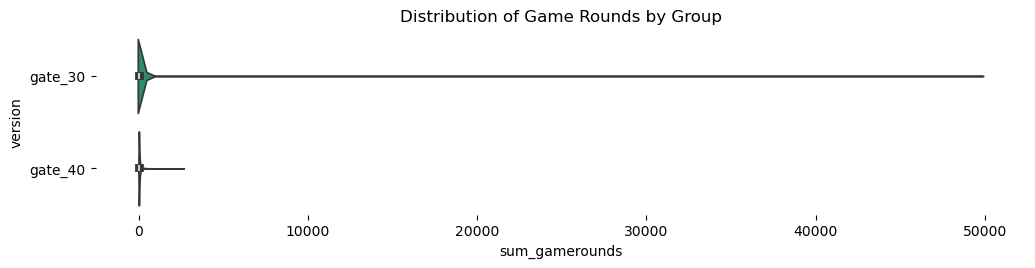

In [31]:
figsize = (12, 1.2 * len(df['version'].unique()))
plt.figure(figsize=figsize)

sns.violinplot(df, x='sum_gamerounds', y='version', hue='version', inner='box', palette='Dark2', legend=False)
sns.despine(top=True, right=True, bottom=True, left=True)
plt.title('Distribution of Game Rounds by Group')
plt.show()

Distribution is highly right-skewed with presence of extreme outliers. Especially for version gate_30.

### 5. Outliers

In [30]:
df.groupby('version')['sum_gamerounds'].quantile([0.95, 0.99])

version      
gate_30  0.95    222.00
         0.99    493.00
gate_40  0.95    220.00
         0.99    492.12
Name: sum_gamerounds, dtype: float64

A small number of users play significantly more rounds, which may impact mean-based comparisons.

In [34]:
df.groupby('version')['sum_gamerounds'].agg(['mean', 'median', 'std', 'min', 'max'])

,mean,median,std,min,max
version,,,,,
gate_30,52.456264,17.0,256.716423,0,49854
gate_40,51.298776,16.0,103.294416,0,2640


Since the distribution is right-skewed, mean-based comparisons may be slightly influenced by high-activity users. Therefore, it is useful to complement the analysis with distribution-based methods or non-parametric tests.

### 6. Retention Comparison

In [32]:
retention = df.groupby('version')[['retention_1', 'retention_7']].mean()
retention

,retention_1,retention_7
version,,
gate_30,0.448188,0.190201
gate_40,0.442283,0.182000


- Initial observation suggests slight differences in retention between groups.
- Statistical testing is required to determine significance.

### 7. Key Observations

- Dataset is clean: no missing values or duplicate users detected  
- A/B groups are well balanced with minor difference in size  
- Engagement (sum_gamerounds) appears higher in gate_30 group  
- Retention differences between groups are small at first glance  
- Distribution of gameplay is highly skewed, with potential outliers  

Further statistical testing is required to confirm whether observed differences are significant.